# LSAS Data Generation And Analysis

This notebook helps you:

1. Generate cyclic SCM datasets and store them in `NeurIPS_2026/data/generated`
2. List all available generated datasets
3. Select one dataset and run the LSAS algorithm on it


In [1]:
from pathlib import Path
import sys

import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name != "NeurIPS_2026":
    candidates = [
        NOTEBOOK_DIR / "NeurIPS_2026",
        NOTEBOOK_DIR.parent / "NeurIPS_2026",
    ]
    for candidate in candidates:
        if candidate.exists():
            NOTEBOOK_DIR = candidate
            break

PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_DIR = NOTEBOOK_DIR / "data"
GENERATED_DIR = DATA_DIR / "generated"
LSAS_DIR = NOTEBOOK_DIR / "Li_et_al_neurips_2025"

GENERATED_DIR.mkdir(parents=True, exist_ok=True)

for path in [str(DATA_DIR), str(LSAS_DIR)]:
    if path not in sys.path:
        sys.path.insert(0, path)

from generate_cyclic_scm_csv import generate_cyclic_scm_edge_dataframe
from LSAS import alg_LSAS

print(f"Project root: {PROJECT_ROOT}")
print(f"Generated data folder: {GENERATED_DIR}")


Project root: c:\Users\gijsv\OneDrive - Universiteit Leiden\phd\code\gutmicrobiome\gutmicrobiome
Generated data folder: c:\Users\gijsv\OneDrive - Universiteit Leiden\phd\code\gutmicrobiome\gutmicrobiome\NeurIPS_2026\data\generated


## Generate A Dataset

Edit the parameters below and run the cell to generate a new CSV in `data/generated`.

In [2]:
generation_config = {
    "output_path": GENERATED_DIR / "output.csv",
    "scm_type": "linear",  # "linear" or "nonlinear"
    "n_nodes": 10,
    "n_edges": 20,
    "n_samples": 5000,
    "n_observed": 5,
    "n_graphs": 1,
    "treatment": 0,
    "outcome": 1,
    "sigma_range": (1.0, 1.0),
    "noise_type": "gaussian",
    "target_operator_norm": 0.8,
    "rng_seed": 12,
    "n_mc_samples": 5000,
    "intervention_low": 0.0,
    "intervention_high": 1.0,
    "pretreatment_flag": True,
    "treatment_outcome_edge": True,
    "require_weak_connectivity": True,
    "require_observed_edge": True,
    "max_generation_attempts": 200,
    "cyclic_flag":False,
    "treatment_outcome_edge": False,
}

generated_frame = generate_cyclic_scm_edge_dataframe(**generation_config)
generated_path = Path(generated_frame.attrs["output_path"])

print(f"Wrote {len(generated_frame)} rows to {generated_path}")
true_ce = generated_frame.attrs["true_ce"]
if isinstance(true_ce, (int, float)):
    print(f"True CE: {true_ce:.6f}")
else:
    print(f"True CE: {true_ce}")
generated_frame.head()


Wrote 5000 rows to c:\Users\gijsv\OneDrive - Universiteit Leiden\phd\code\gutmicrobiome\gutmicrobiome\NeurIPS_2026\data\generated\output_acyclic_linear_graphs1_n5000_nodes10_edges20_t0_y1_20260501-1640.csv
True CE: 0.000000


,graph_id,sample_id,n_graphs,graph_family,allows_two_cycles,x_singleton_scc_flag,scm_type,treatment,outcome,treatment_outcome_edge,...,has_sigma_backdoor,sigma_backdoor_checked,graph_structure,node_0,node_1,node_2,node_4,node_5,node_8,node_9
0,0,0,1,acyclic,False,True,linear,0,1,False,...,NA,False,"{4->0,5->0,6->0,8->0,2->1,3->1,6->1,9->1,5->2,...",-0.914152,1.637951,0.026112,1.134007,-0.590532,-0.586329,1.468730
1,0,1,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,-0.881377,1.184857,0.927391,-0.190750,0.975917,-0.147611,1.053076
2,0,2,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,-0.449374,0.113165,1.746446,0.894822,-0.045891,-0.170541,-0.471497
3,0,3,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,2.500054,1.402980,1.549501,-1.040465,-1.245417,-1.554178,-0.403423
4,0,4,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,-0.524361,0.764857,0.193766,-0.355282,0.073414,-2.089337,-0.192373


## Show Available Generated Files

Run this cell to see which datasets are currently available in `data/generated`.

In [3]:
available_files = sorted(GENERATED_DIR.glob("*.csv"))

available_files_df = pd.DataFrame(
    {
        "file_index": list(range(len(available_files))),
        "file_name": [path.name for path in available_files],
        "file_size_bytes": [path.stat().st_size for path in available_files],
    }
)

available_files_df


,file_index,file_name,file_size_bytes
0,0,output_acyclic_linear_graphs1_n5000_nodes10_ed...,950006
1,1,output_acyclic_linear_graphs1_n5000_nodes10_ed...,950006


## Select A Dataset

Choose either `selected_file_index` from the table above or set `selected_file_name` directly.

In [4]:
selected_file_index = 0
selected_file_name = None

if selected_file_name is not None:
    selected_path = GENERATED_DIR / selected_file_name
else:
    if not available_files:
        raise FileNotFoundError(f"No CSV files found in {GENERATED_DIR}")
    selected_path = available_files[selected_file_index]

print(f"Selected file: {selected_path.name}")
selected_path


Selected file: output_acyclic_linear_graphs1_n5000_nodes10_edges20_t0_y1_20260501-1601.csv


WindowsPath('c:/Users/gijsv/OneDrive - Universiteit Leiden/phd/code/gutmicrobiome/gutmicrobiome/NeurIPS_2026/data/generated/output_acyclic_linear_graphs1_n5000_nodes10_edges20_t0_y1_20260501-1601.csv')

## Preview Loaded Graph

This cell loads the selected CSV graph metadata and draws the stored directed graph structure.

Loaded graph with 10 nodes and 20 directed edges.


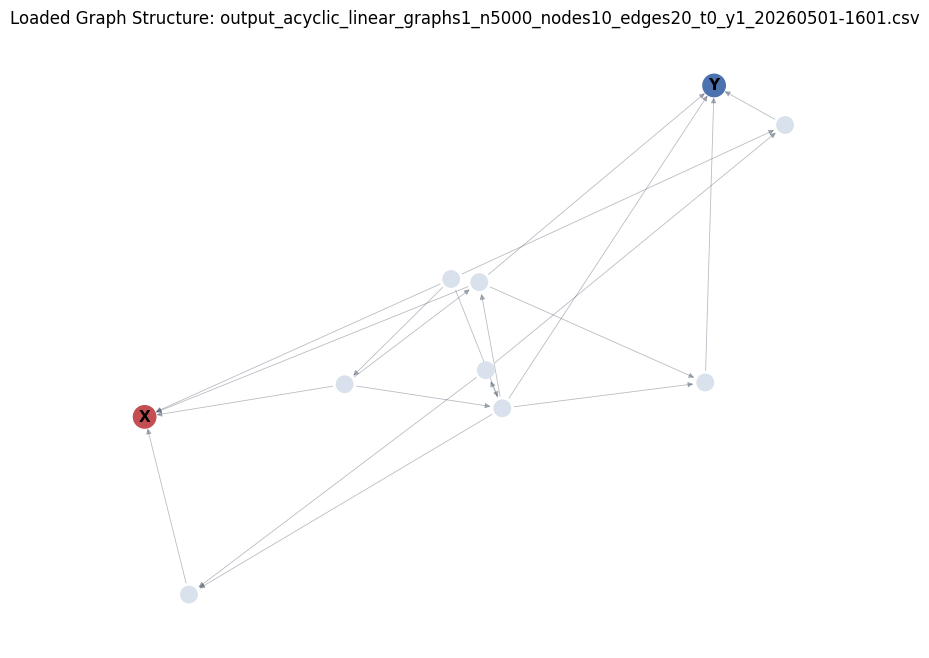

In [5]:
import matplotlib.pyplot as plt
import networkx as nx

graph_metadata = pd.read_csv(selected_path, nrows=1)

if "graph_structure" not in graph_metadata.columns:
    raise ValueError("Selected CSV does not contain a graph_structure column.")

graph_structure_text = str(graph_metadata["graph_structure"].iloc[0])
n_nodes = int(graph_metadata["n_nodes"].iloc[0])
treatment_node = int(graph_metadata["treatment"].iloc[0])
outcome_node = int(graph_metadata["outcome"].iloc[0])

graph = nx.DiGraph()
graph.add_nodes_from(range(n_nodes))

edge_text = graph_structure_text.strip().strip("{}")
if edge_text and edge_text != "NA":
    for edge in edge_text.split(","):
        parent_text, child_text = edge.split("->")
        graph.add_edge(int(parent_text), int(child_text))

print(
    f"Loaded graph with {graph.number_of_nodes()} nodes and "
    f"{graph.number_of_edges()} directed edges."
)

if graph.number_of_nodes() <= 150:
    positions = nx.spring_layout(graph, seed=7, iterations=40)
else:
    positions = nx.random_layout(graph, seed=7)

node_colors = [
    "#c44e52" if node == treatment_node else "#4c72b0" if node == outcome_node else "#d9e2ec"
    for node in graph.nodes
]
node_sizes = [
    260 if node in {treatment_node, outcome_node} else max(12, 1400 / max(n_nodes, 1))
    for node in graph.nodes
]
labels = {treatment_node: "X", outcome_node: "Y"}

fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_nodes(graph, positions, node_color=node_colors, node_size=node_sizes, ax=ax)
nx.draw_networkx_edges(
    graph,
    positions,
    arrows=True,
    arrowsize=8,
    width=0.6,
    alpha=0.35,
    edge_color="#344054",
    ax=ax,
)
nx.draw_networkx_labels(graph, positions, labels=labels, font_size=11, font_weight="bold", ax=ax)
ax.set_title(f"Loaded Graph Structure: {selected_path.name}")
ax.set_axis_off()
plt.show()


## Run LSAS On The Selected Dataset

This cell loads the selected CSV, keeps the visible node columns, infers the treatment and outcome variable names from the file metadata, and runs LSAS.

In [6]:
mb_method = "TC"  # options: "TC", "IAMB", "Fast_IAMB", "HITON_MB"

dataset_frame = pd.read_csv(selected_path)
node_columns = sorted(
    [column for column in dataset_frame.columns if column.startswith("node_")],
    key=lambda name: int(name.split("_")[1]),
)

if not node_columns:
    raise ValueError("Selected CSV does not contain any node columns.")

lsas_data = dataset_frame[node_columns].copy()
treatment_node = int(dataset_frame["treatment"].iloc[0])
outcome_node = int(dataset_frame["outcome"].iloc[0])
treatment_var = f"node_{treatment_node}"
outcome_var = f"node_{outcome_node}"

print(f"Using treatment variable: {treatment_var}")
print(f"Using outcome variable: {outcome_var}")
print(f"Visible node columns: {node_columns}")

lsas_result = alg_LSAS(
    lsas_data,
    Tr_X=treatment_var,
    Out_Y=outcome_var,
    mb_method=mb_method,
)

lsas_result


Using treatment variable: node_0
Using outcome variable: node_1
Visible node columns: ['node_0', 'node_1', 'node_2', 'node_4', 'node_5', 'node_8', 'node_9']


{'VASs': 0, 'ATE': None, 'CI_num': 12}